In [15]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from math import sqrt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05

print("Project root:", PROJECT_ROOT)
print("Data exists:", DATA_PATH.exists())

Project root: /Users/hkkkkjv/Study/memory/4 course/boot/ecommerce-product-analytics
Data exists: True


In [16]:
events = pd.read_csv(DATA_PATH)

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

events = events.sort_values("timestamp").reset_index(drop=True)

print("Shape:", events.shape)
print("Unique users:", events["visitorid"].nunique())
print("Period:", events["timestamp"].min(), "—", events["timestamp"].max())

display(events.head())

Shape: (2756101, 5)
Unique users: 1407580
Period: 2015-05-03 03:00:04.384000+00:00 — 2015-09-18 02:59:47.788000+00:00


,timestamp,visitorid,event,itemid,transactionid
0,2015-05-03 03:00:04.384+00:00,693516,addtocart,297662,NaN
1,2015-05-03 03:00:11.289+00:00,829044,view,60987,NaN
2,2015-05-03 03:00:13.048+00:00,652699,view,252860,NaN
3,2015-05-03 03:00:24.154+00:00,1125936,view,33661,NaN
4,2015-05-03 03:00:26.228+00:00,693516,view,297662,NaN


In [17]:
user_features = (
    events.groupby("visitorid")
    .agg(
        total_events=("event", "size"),
        views=("event", lambda x: (x == "view").sum()),
        addtocarts=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum()),
        unique_items=("itemid", "nunique"),
        first_event=("timestamp", "min"),
        last_event=("timestamp", "max"),
        active_days=("timestamp", lambda x: x.dt.date.nunique())
    )
    .reset_index()
)

user_features["is_purchaser"] = (
    user_features["transactions"] > 0
).astype(int)

user_features["first_event_weekday"] = (
    user_features["first_event"].dt.day_name()
)

user_features["first_event_month"] = (
    user_features["first_event"]
    .dt.tz_localize(None)
    .dt.to_period("M")
    .astype(str)
)

user_features["observation_days"] = (
    user_features["last_event"] - user_features["first_event"]
).dt.total_seconds() / 86400

display(user_features.head())

print("User-level dataset:", user_features.shape)
print("Missing values:", user_features.isna().sum().sum())

,visitorid,total_events,views,addtocarts,transactions,unique_items,first_event,last_event,active_days,is_purchaser,first_event_weekday,first_event_month,observation_days
0,0,3,3,0,0,3,2015-09-11 20:49:49.439+00:00,2015-09-11 20:55:17.175+00:00,1,0,Friday,2015-09,0.003793
1,1,1,1,0,0,1,2015-08-13 17:46:06.444+00:00,2015-08-13 17:46:06.444+00:00,1,0,Thursday,2015-08,0.000000
2,2,8,8,0,0,4,2015-08-07 17:51:44.567+00:00,2015-08-07 18:20:57.845+00:00,1,0,Friday,2015-08,0.020293
3,3,1,1,0,0,1,2015-08-01 07:10:35.296+00:00,2015-08-01 07:10:35.296+00:00,1,0,Saturday,2015-08,0.000000
4,4,1,1,0,0,1,2015-09-15 21:24:27.167+00:00,2015-09-15 21:24:27.167+00:00,1,0,Tuesday,2015-09,0.000000


User-level dataset: (1407580, 13)
Missing values: 0


In [18]:
assert user_features["visitorid"].is_unique
assert user_features["is_purchaser"].isin([0, 1]).all()
assert user_features["total_events"].ge(1).all()

print("User-level validation passed.")

User-level validation passed.


In [19]:
transactions_data = events[
    events["event"] == "transaction"
].copy()

orders_per_user = (
    transactions_data
    .groupby("visitorid")["transactionid"]
    .nunique()
    .rename("orders_count")
)

user_features = user_features.merge(
    orders_per_user,
    on="visitorid",
    how="left"
)

user_features["orders_count"] = (
    user_features["orders_count"]
    .fillna(0)
    .astype(int)
)

user_features["is_repeat_buyer"] = (
    user_features["orders_count"] > 1
).astype(int)

buyers = user_features[
    user_features["orders_count"] > 0
]

repeat_buyers = user_features[
    user_features["orders_count"] > 1
]

print("Buyers:", len(buyers))
print("Repeat buyers:", len(repeat_buyers))
print(
    "Repeat purchase rate:",
    len(repeat_buyers) / len(buyers)
)

Buyers: 11719
Repeat buyers: 1063
Repeat purchase rate: 0.09070739824217083


In [20]:
metrics = [
    "total_events",
    "views",
    "addtocarts",
    "transactions",
    "unique_items",
    "active_days",
    "observation_days"
]

descriptive_stats = (
    user_features[metrics]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
    .T
)

display(descriptive_stats.round(3))

descriptive_stats.to_csv(
    TABLES_DIR / "08_descriptive_statistics.csv"
)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_events,1407580.0,1.958,12.580,1.0,1.0,1.0,2.000,3.00,5.00,13.000,7757.000
views,1407580.0,1.893,10.994,0.0,1.0,1.0,2.000,3.00,5.00,12.000,6479.000
addtocarts,1407580.0,0.049,1.165,0.0,0.0,0.0,0.000,0.00,0.00,1.000,719.000
transactions,1407580.0,0.016,0.826,0.0,0.0,0.0,0.000,0.00,0.00,0.000,559.000
unique_items,1407580.0,1.524,7.144,1.0,1.0,1.0,1.000,2.00,3.00,8.000,3814.000
active_days,1407580.0,1.172,0.928,1.0,1.0,1.0,1.000,2.00,2.00,4.000,131.000
observation_days,1407580.0,2.375,11.631,0.0,0.0,0.0,0.001,0.48,10.31,69.089,137.973


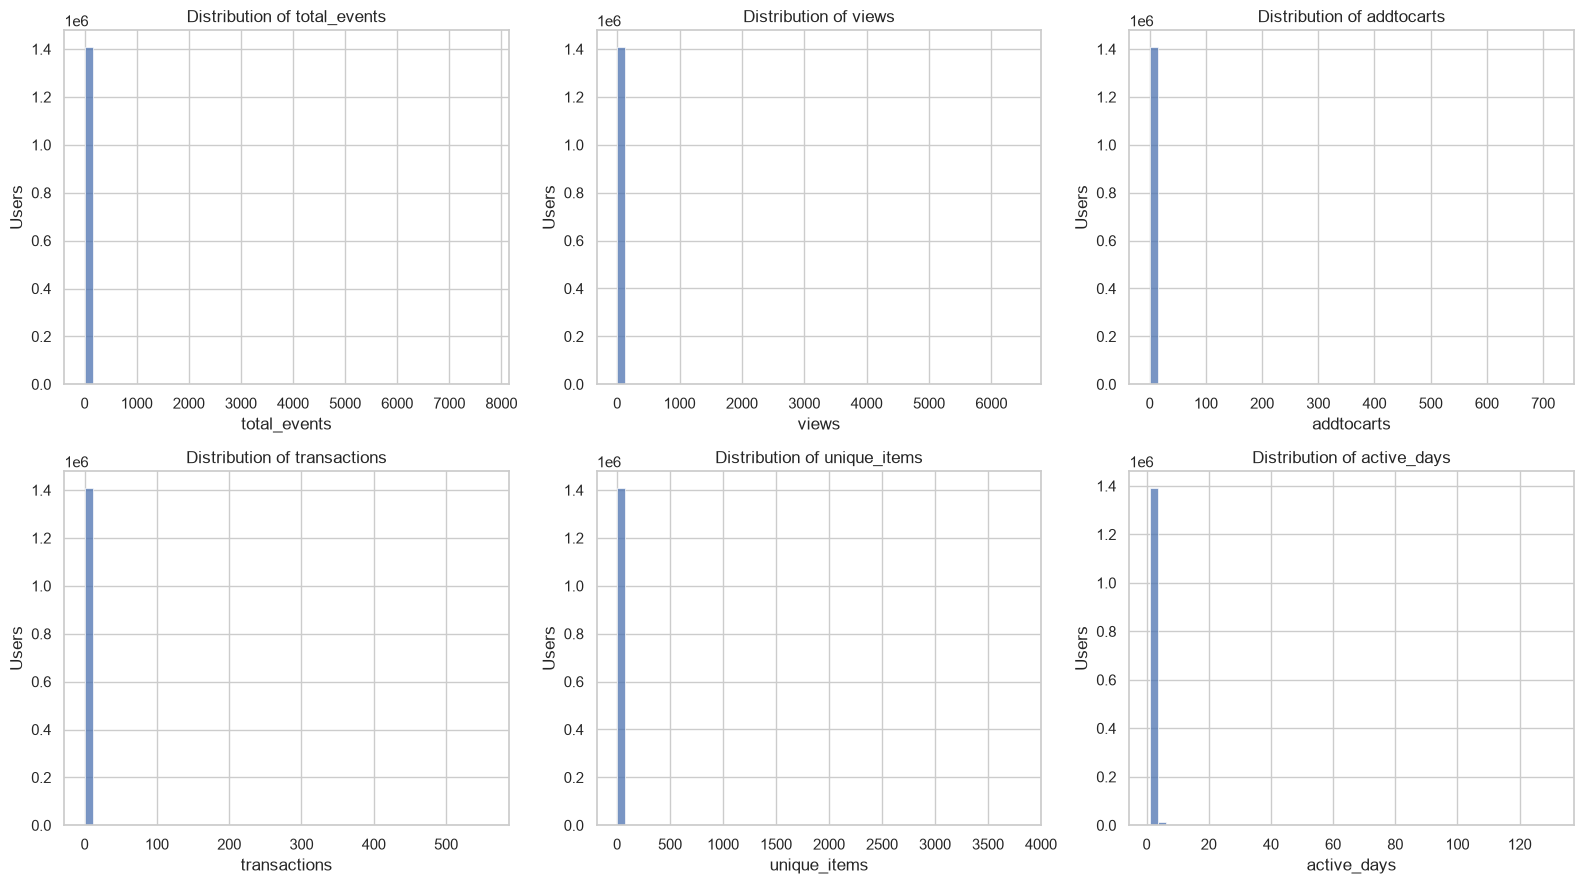

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

plot_metrics = [
    "total_events",
    "views",
    "addtocarts",
    "transactions",
    "unique_items",
    "active_days"
]

for ax, metric in zip(axes.flat, plot_metrics):
    sns.histplot(
        user_features[metric],
        bins=50,
        ax=ax
    )
    ax.set_title(f"Distribution of {metric}")
    ax.set_xlabel(metric)
    ax.set_ylabel("Users")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_user_metrics_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [22]:
skewness = user_features[metrics].skew()

skewness_table = (
    skewness
    .rename("skewness")
    .to_frame()
    .sort_values("skewness", ascending=False)
)

display(skewness_table.round(3))

,skewness
transactions,364.657
addtocarts,283.203
total_events,269.506
views,247.635
unique_items,219.172
active_days,32.611
observation_days,6.502


In [23]:
def wilson_interval(successes, total, confidence=0.95):
    if total == 0:
        return np.nan, np.nan

    z = stats.norm.ppf(1 - (1 - confidence) / 2)

    p = successes / total
    denominator = 1 + z**2 / total

    center = (
        p + z**2 / (2 * total)
    ) / denominator

    margin = (
        z * sqrt(
            p * (1 - p) / total
            + z**2 / (4 * total**2)
        )
    ) / denominator

    return center - margin, center + margin


total_users = len(user_features)

buyers = user_features[
    user_features["is_purchaser"] == 1
]

repeat_buyers = buyers[
    buyers["orders_count"] > 1
]

cart_users = user_features[
    user_features["addtocarts"] > 0
]

purchasers_with_cart = cart_users[
    cart_users["is_purchaser"] == 1
]

proportion_metrics = {
    "Purchase rate": (
        len(buyers),
        total_users
    ),
    "Repeat purchase rate": (
        len(repeat_buyers),
        len(buyers)
    ),
    "Add-to-cart rate": (
        len(cart_users),
        total_users
    ),
    "Purchase rate among cart users": (
        len(purchasers_with_cart),
        len(cart_users)
    )
}

ci_results = []

for name, (successes, total) in proportion_metrics.items():
    rate = successes / total
    lower, upper = wilson_interval(successes, total)

    ci_results.append({
        "metric": name,
        "successes": successes,
        "total": total,
        "rate": rate,
        "ci_lower": lower,
        "ci_upper": upper
    })

ci_table = pd.DataFrame(ci_results)

display(ci_table.round(4))

ci_table.to_csv(
    TABLES_DIR / "08_proportion_confidence_intervals.csv",
    index=False
)

,metric,successes,total,rate,ci_lower,ci_upper
0,Purchase rate,11719,1407580,0.0083,0.0082,0.0085
1,Repeat purchase rate,1063,11719,0.0907,0.0856,0.0960
2,Add-to-cart rate,37722,1407580,0.0268,0.0265,0.0271
3,Purchase rate among cart users,10576,37722,0.2804,0.2759,0.2849


In [24]:
lower, upper = wilson_interval(
    len(repeat_buyers),
    len(buyers)
)

print(f"Repeat Purchase Rate: {len(repeat_buyers) / len(buyers):.2%}")
print(f"95% CI: [{lower:.2%}, {upper:.2%}]")

Repeat Purchase Rate: 9.07%
95% CI: [8.56%, 9.60%]


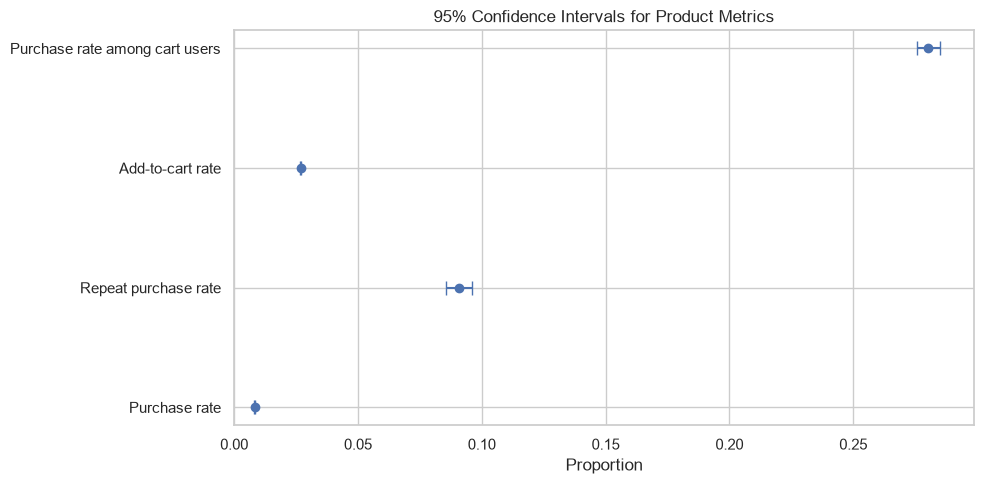

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))

y = np.arange(len(ci_table))

ax.errorbar(
    ci_table["rate"],
    y,
    xerr=[
        ci_table["rate"] - ci_table["ci_lower"],
        ci_table["ci_upper"] - ci_table["rate"]
    ],
    fmt="o",
    capsize=5
)

ax.set_yticks(y)
ax.set_yticklabels(ci_table["metric"])
ax.set_xlabel("Proportion")
ax.set_title("95% Confidence Intervals for Product Metrics")
ax.set_xlim(left=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_proportion_confidence_intervals.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [26]:
def bootstrap_ci(
    values,
    statistic=np.mean,
    n_bootstrap=500,
    sample_size=100_000,
    confidence=0.95,
    random_state=42
):
    values = np.asarray(values)
    values = values[~pd.isna(values)]

    rng = np.random.default_rng(random_state)
    
    if len(values) > sample_size:
        values = rng.choice(
            values,
            size=sample_size,
            replace=False
        )

    bootstrap_stats = []

    for _ in range(n_bootstrap):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )

        bootstrap_stats.append(statistic(sample))

    alpha = 1 - confidence

    return {
        "estimate": statistic(values),
        "ci_lower": np.quantile(bootstrap_stats, alpha / 2),
        "ci_upper": np.quantile(bootstrap_stats, 1 - alpha / 2),
        "sample_size": len(values),
        "n_bootstrap": n_bootstrap
    }

In [27]:
bootstrap_results = []

bootstrap_metrics = [
    "total_events",
    "views",
    "active_days"
]

for metric in bootstrap_metrics:
    for statistic_name, statistic_func in [
        ("mean", np.mean),
        ("median", np.median)
    ]:
        result = bootstrap_ci(
            user_features[metric].values,
            statistic=statistic_func,
            n_bootstrap=2000,
            random_state=RANDOM_STATE
        )

        bootstrap_results.append({
            "metric": metric,
            "statistic": statistic_name,
            **result
        })

bootstrap_table = pd.DataFrame(bootstrap_results)

display(bootstrap_table.round(3))

bootstrap_table.to_csv(
    TABLES_DIR / "08_bootstrap_confidence_intervals.csv",
    index=False
)

,metric,statistic,estimate,ci_lower,ci_upper,sample_size,n_bootstrap
0,total_events,mean,1.957,1.901,2.027,100000,2000
1,total_events,median,1.000,1.000,1.000,100000,2000
2,views,mean,1.890,1.842,1.951,100000,2000
3,views,median,1.000,1.000,1.000,100000,2000
4,active_days,mean,1.171,1.166,1.176,100000,2000
5,active_days,median,1.000,1.000,1.000,100000,2000


In [28]:
def mann_whitney_analysis(
    data,
    metric,
    group_column="is_purchaser"
):
    group_0 = data.loc[
        data[group_column] == 0,
        metric
    ].dropna()

    group_1 = data.loc[
        data[group_column] == 1,
        metric
    ].dropna()

    test = stats.mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )

    n0 = len(group_0)
    n1 = len(group_1)

    # Rank-biserial correlation
    rank_biserial = 1 - (
        2 * test.statistic / (n0 * n1)
    )

    return {
        "metric": metric,
        "n_non_purchasers": n0,
        "n_purchasers": n1,
        "median_non_purchasers": group_0.median(),
        "median_purchasers": group_1.median(),
        "mean_non_purchasers": group_0.mean(),
        "mean_purchasers": group_1.mean(),
        "u_statistic": test.statistic,
        "p_value": test.pvalue,
        "rank_biserial": rank_biserial
    }

In [29]:
comparison_metrics = [
    "total_events",
    "views",
    "unique_items",
    "active_days",
    "observation_days"
]

test_results = []

for metric in comparison_metrics:
    test_results.append(
        mann_whitney_analysis(
            user_features,
            metric
        )
    )

tests_table = pd.DataFrame(test_results)

display(tests_table.round(4))

,metric,n_non_purchasers,n_purchasers,median_non_purchasers,median_purchasers,mean_non_purchasers,mean_purchasers,u_statistic,p_value,rank_biserial
0,total_events,1395861,11719,1.0,6.0000,1.8092,19.6841,8.556367e+08,0.0,0.8954
1,views,1395861,11719,1.0,4.0000,1.7792,15.4240,3.421265e+09,0.0,0.5817
2,unique_items,1395861,11719,1.0,2.0000,1.4567,9.5383,4.408195e+09,0.0,0.4610
3,active_days,1395861,11719,1.0,1.0000,1.1621,2.3372,5.387762e+09,0.0,0.3413
4,observation_days,1395861,11719,0.0,0.0697,2.3084,10.3664,1.804275e+09,0.0,0.7794


In [30]:
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)

    n = len(p_values)
    order = np.argsort(p_values)

    sorted_p = p_values[order]

    adjusted = sorted_p * n / np.arange(1, n + 1)

    adjusted = np.minimum.accumulate(
        adjusted[::-1]
    )[::-1]

    adjusted = np.clip(adjusted, 0, 1)

    result = np.empty(n)
    result[order] = adjusted

    return result


tests_table["p_value_adjusted"] = benjamini_hochberg(
    tests_table["p_value"]
)

tests_table["significant"] = (
    tests_table["p_value_adjusted"] < ALPHA
)

display(
    tests_table[
        [
            "metric",
            "p_value",
            "p_value_adjusted",
            "significant",
            "rank_biserial"
        ]
    ].round(5)
)

tests_table.to_csv(
    TABLES_DIR / "08_mann_whitney_tests.csv",
    index=False
)

,metric,p_value,p_value_adjusted,significant,rank_biserial
0,total_events,0.0,0.0,True,0.89539
1,views,0.0,0.0,True,0.58170
2,unique_items,0.0,0.0,True,0.46104
3,active_days,0.0,0.0,True,0.34127
4,observation_days,0.0,0.0,True,0.77940


In [31]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_table = pd.crosstab(
    user_features["first_event_weekday"],
    user_features["is_purchaser"]
).reindex(weekday_order, fill_value=0)

weekday_table.columns = [
    "Non-purchasers",
    "Purchasers"
]

weekday_table["purchase_rate"] = (
    weekday_table["Purchasers"]
    / (
        weekday_table["Purchasers"]
        + weekday_table["Non-purchasers"]
    )
)

display(weekday_table.round(4))

,Non-purchasers,Purchasers,purchase_rate
first_event_weekday,,,
Monday,221126,2062,0.0092
Tuesday,222604,2132,0.0095
Wednesday,214915,2062,0.0095
Thursday,208840,1777,0.0084
Friday,192154,1474,0.0076
Saturday,160255,994,0.0062
Sunday,175967,1218,0.0069


In [32]:
contingency_table = weekday_table[
    ["Non-purchasers", "Purchasers"]
]

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

n = contingency_table.to_numpy().sum()

rows, columns = contingency_table.shape

cramers_v = sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("Cramer's V:", cramers_v)

print(
    "Statistically significant:",
    p_value < ALPHA
)

Chi-square statistic: 244.36728857639827
Degrees of freedom: 6
p-value: 6.55272929967633e-50
Cramer's V: 0.013176042631090032
Statistically significant: True


In [33]:
expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_table.round(2))

print(
    "Minimum expected frequency:",
    expected_table.to_numpy().min()
)

,Non-purchasers,Purchasers
first_event_weekday,,
Monday,221329.82,1858.18
Tuesday,222864.93,1871.07
Wednesday,215170.53,1806.47
Thursday,208863.48,1753.52
Friday,192015.92,1612.08
Saturday,159906.50,1342.50
Sunday,175709.82,1475.18


Minimum expected frequency: 1342.5006258969295


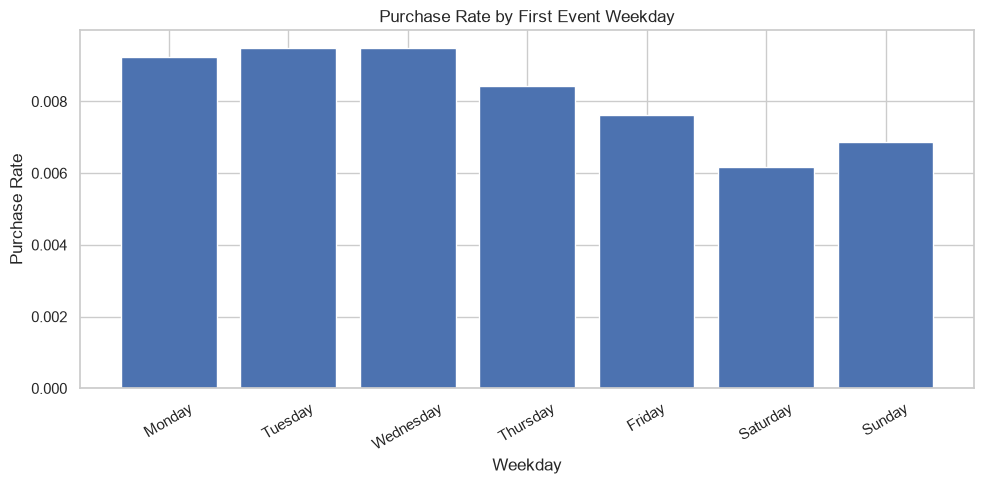

In [34]:
fig, ax = plt.subplots(figsize=(10, 5))

weekday_rates = weekday_table["purchase_rate"]

ax.bar(
    weekday_rates.index,
    weekday_rates.values
)

ax.set_title("Purchase Rate by First Event Weekday")
ax.set_xlabel("Weekday")
ax.set_ylabel("Purchase Rate")

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_purchase_rate_by_weekday.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [35]:
correlation_metrics = [
    "total_events",
    "views",
    "addtocarts",
    "transactions",
    "unique_items",
    "active_days",
    "observation_days"
]

correlation_matrix = user_features[
    correlation_metrics
].corr(method="spearman")

display(correlation_matrix.round(3))

correlation_matrix.to_csv(
    TABLES_DIR / "08_spearman_correlation_matrix.csv"
)

,total_events,views,addtocarts,transactions,unique_items,active_days,observation_days
total_events,1.000,0.981,0.275,0.177,0.826,0.561,0.978
views,0.981,1.000,0.153,0.115,0.829,0.566,0.962
addtocarts,0.275,0.153,1.000,0.498,0.167,0.126,0.236
transactions,0.177,0.115,0.498,1.000,0.103,0.102,0.153
unique_items,0.826,0.829,0.167,0.103,1.000,0.516,0.800
active_days,0.561,0.566,0.126,0.102,0.516,1.000,0.654
observation_days,0.978,0.962,0.236,0.153,0.800,0.654,1.000


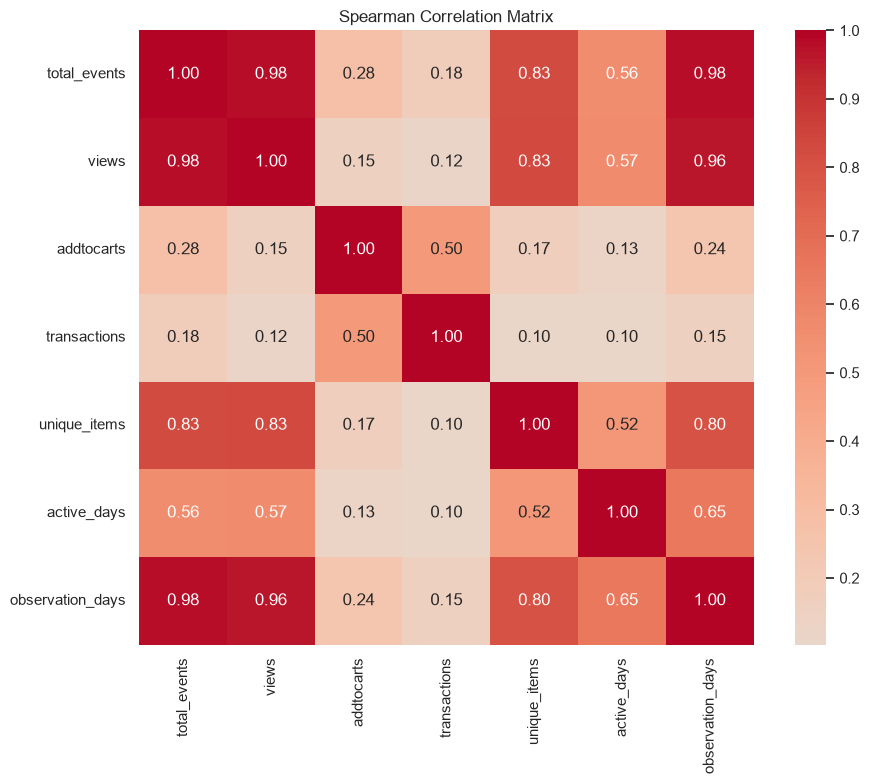

In [36]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    ax=ax
)

ax.set_title("Spearman Correlation Matrix")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_spearman_correlation_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [37]:
correlation_pairs = [
    ("views", "addtocarts"),
    ("views", "transactions"),
    ("addtocarts", "transactions"),
    ("total_events", "unique_items"),
    ("active_days", "total_events")
]

correlation_results = []

for x, y in correlation_pairs:
    result = stats.spearmanr(
        user_features[x],
        user_features[y]
    )

    correlation_results.append({
        "metric_1": x,
        "metric_2": y,
        "spearman_r": result.statistic,
        "p_value": result.pvalue
    })

correlation_tests = pd.DataFrame(
    correlation_results
)

correlation_tests["p_value_adjusted"] = (
    benjamini_hochberg(
        correlation_tests["p_value"]
    )
)

correlation_tests["significant"] = (
    correlation_tests["p_value_adjusted"] < ALPHA
)

display(correlation_tests.round(5))

correlation_tests.to_csv(
    TABLES_DIR / "08_correlation_tests.csv",
    index=False
)

,metric_1,metric_2,spearman_r,p_value,p_value_adjusted,significant
0,views,addtocarts,0.15336,0.0,0.0,True
1,views,transactions,0.11546,0.0,0.0,True
2,addtocarts,transactions,0.49785,0.0,0.0,True
3,total_events,unique_items,0.82576,0.0,0.0,True
4,active_days,total_events,0.56141,0.0,0.0,True


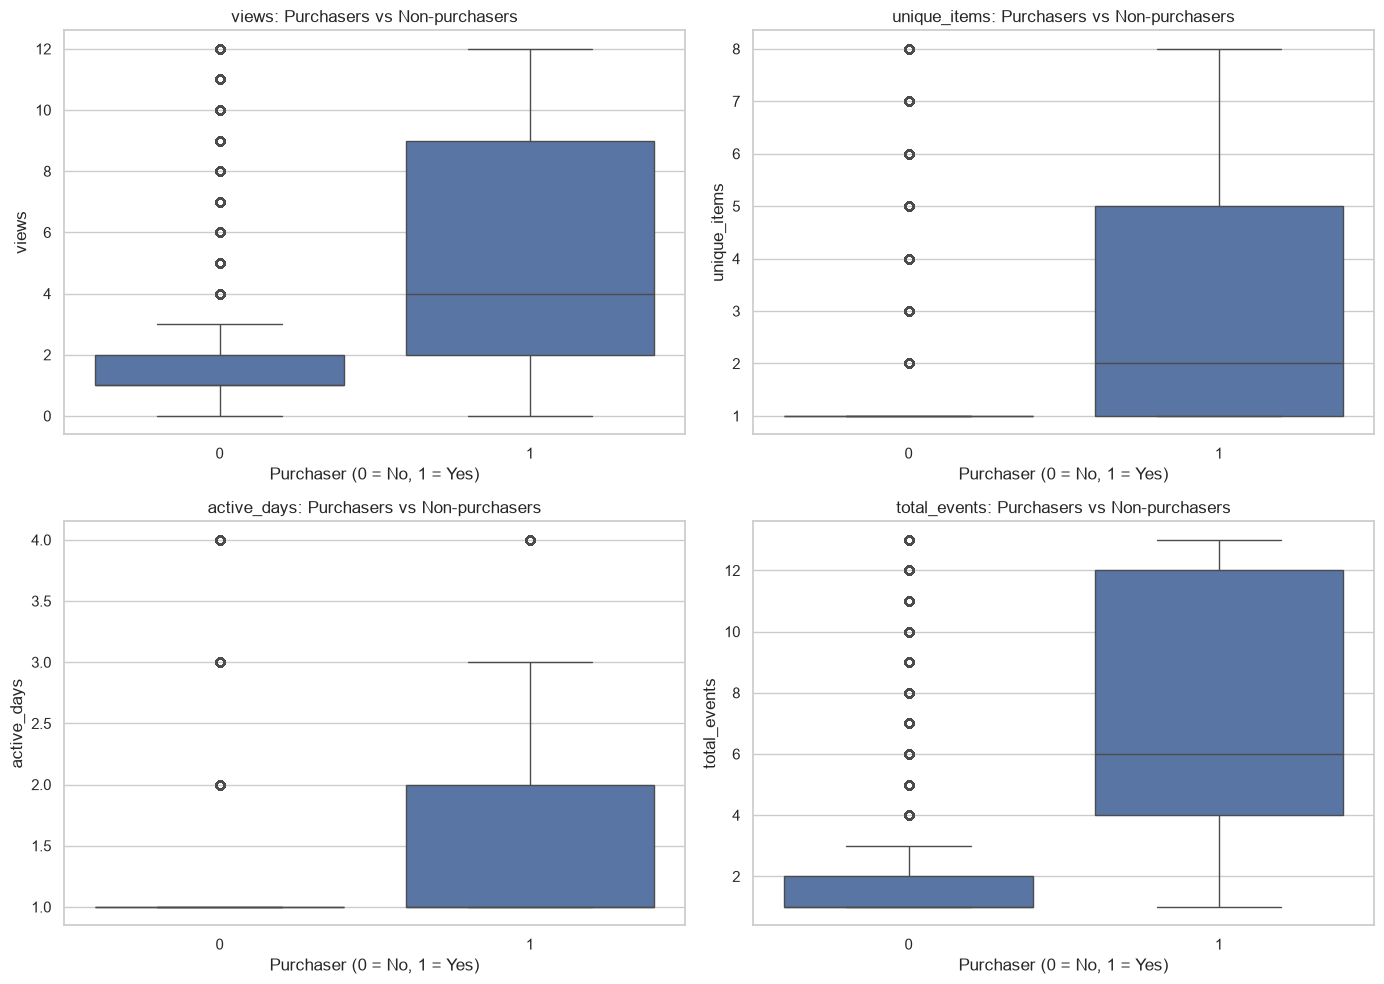

In [38]:
behavior_metrics = [
    "views",
    "unique_items",
    "active_days",
    "total_events"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, metric in zip(axes.flat, behavior_metrics):
    upper_limit = user_features[metric].quantile(0.99)

    plot_data = user_features.copy()

    plot_data[metric] = plot_data[metric].clip(
        upper=upper_limit
    )

    sns.boxplot(
        data=plot_data,
        x="is_purchaser",
        y=metric,
        ax=ax
    )

    ax.set_title(f"{metric}: Purchasers vs Non-purchasers")
    ax.set_xlabel("Purchaser (0 = No, 1 = Yes)")
    ax.set_ylabel(metric)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_purchaser_behavior_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [39]:
summary = {
    "total_users": len(user_features),
    "purchasers": int(user_features["is_purchaser"].sum()),
    "purchase_rate": user_features["is_purchaser"].mean(),
    "mean_events_per_user": user_features["total_events"].mean(),
    "median_events_per_user": user_features["total_events"].median(),
    "mean_views_per_user": user_features["views"].mean(),
    "median_views_per_user": user_features["views"].median(),
    "mean_active_days": user_features["active_days"].mean(),
    "median_active_days": user_features["active_days"].median()
}

summary_table = pd.DataFrame(
    summary.items(),
    columns=["metric", "value"]
)

display(summary_table.round(4))

summary_table.to_csv(
    TABLES_DIR / "08_statistical_summary.csv",
    index=False
)

,metric,value
0,total_users,1.407580e+06
1,purchasers,1.171900e+04
2,purchase_rate,8.300000e-03
3,mean_events_per_user,1.958000e+00
4,median_events_per_user,1.000000e+00
5,mean_views_per_user,1.892800e+00
6,median_views_per_user,1.000000e+00
7,mean_active_days,1.171900e+00
8,median_active_days,1.000000e+00


In [40]:
print("MANN-WHITNEY TESTS")
print("-" * 60)

for _, row in tests_table.iterrows():
    print(
        f"{row['metric']}: "
        f"p_adj={row['p_value_adjusted']:.6g}, "
        f"significant={row['significant']}, "
        f"effect={row['rank_biserial']:.4f}"
    )

print("\nCHI-SQUARE TEST")
print("-" * 60)

print(f"Chi-square: {chi2:.4f}")
print(f"p-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.4f}")

print("\nCORRELATION TESTS")
print("-" * 60)

display(
    correlation_tests[
        [
            "metric_1",
            "metric_2",
            "spearman_r",
            "p_value_adjusted",
            "significant"
        ]
    ].round(5)
)

MANN-WHITNEY TESTS
------------------------------------------------------------
total_events: p_adj=0, significant=True, effect=0.8954
views: p_adj=0, significant=True, effect=0.5817
unique_items: p_adj=0, significant=True, effect=0.4610
active_days: p_adj=0, significant=True, effect=0.3413
observation_days: p_adj=0, significant=True, effect=0.7794

CHI-SQUARE TEST
------------------------------------------------------------
Chi-square: 244.3673
p-value: 6.55273e-50
Cramer's V: 0.0132

CORRELATION TESTS
------------------------------------------------------------


,metric_1,metric_2,spearman_r,p_value_adjusted,significant
0,views,addtocarts,0.15336,0.0,True
1,views,transactions,0.11546,0.0,True
2,addtocarts,transactions,0.49785,0.0,True
3,total_events,unique_items,0.82576,0.0,True
4,active_days,total_events,0.56141,0.0,True


In [41]:
print("Saved tables:")
for path in sorted(TABLES_DIR.glob("08_*.csv")):
    print(path.name)

print("\nSaved figures:")
for path in sorted(FIGURES_DIR.glob("08_*.png")):
    print(path.name)

Saved tables:
08_bootstrap_confidence_intervals.csv
08_correlation_tests.csv
08_descriptive_statistics.csv
08_mann_whitney_tests.csv
08_proportion_confidence_intervals.csv
08_spearman_correlation_matrix.csv
08_statistical_summary.csv

Saved figures:
08_low_purchase_cart_ratio.png
08_proportion_confidence_intervals.png
08_purchase_rate_by_weekday.png
08_purchaser_behavior_comparison.png
08_spearman_correlation_matrix.png
08_user_metrics_distributions.png
